# Single pooled SARIMAX-AR on the full 24-CMA panel (no ensembles)

 locked config: `rollmean_3 + rollmean_12` of chained deltas, `Lasso(0.001)`, pooled over **all 24 CMAs** (7744 fit rows).
This notebook loads **only the artifact** (`artifacts/sarimax_full.joblib`, built by `prediction/train_sarimax_full.py`),
reproduces the test scores bit-exact from `prediction/sarimax_full_predictions_*.csv`, and compares against the chained naive floor.
Target: signed monthly change in total NHPI. Test scored once; short-history CMAs included in fit and eval.
Runs from the repo root or `notebooks/`.


In [1]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

here = Path.cwd()
ROOT = here.parent if here.name == 'notebooks' else here
PRED_DIR = ROOT / 'prediction'
ART_DIR = ROOT / 'artifacts'
OUT_DIR = ROOT / 'notebooks'

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, float) - np.asarray(b, float)) ** 2)))

art = joblib.load(ART_DIR / 'sarimax_full.joblib')
met = json.loads((ART_DIR / 'sarimax_full_metrics.json').read_text())
print('features:', art['features'], '| alpha:', art['alpha'], '| fit_rows:', art['fit_rows'])
print('coef:', np.round(art['model'].coef_, 4), '| intercept:', round(float(art['model'].intercept_), 4))
print(f"artifact test16={met['rmse_16']:.6f} test24={met['rmse_24']:.6f}")
print(f"naive   test16={met['naive_16']:.6f} test24={met['naive_24']:.6f}")


features: ['rollmean_3', 'rollmean_12'] | alpha: 0.001 | fit_rows: 7744
coef: [0.1678 0.0758] | intercept: 0.1277
artifact test16=0.800261 test24=0.760422
naive   test16=0.956390 test24=0.893202


In [2]:
SUBSET16 = ['Edmonton, Alberta', 'Greater Sudbury, Ontario', 'Hamilton, Ontario',
    'Kitchener-Cambridge-Waterloo, Ontario', 'London, Ontario', 'Montréal, Quebec',
    'Ottawa-Gatineau, Ontario part, Ontario/Quebec', 'Québec, Quebec',
    'Regina, Saskatchewan', 'Saskatoon, Saskatchewan',
    'St. Catharines-Niagara, Ontario', "St. John's, Newfoundland and Labrador",
    'Vancouver, British Columbia', 'Victoria, British Columbia',
    'Windsor, Ontario', 'Winnipeg, Manitoba']

fr_test = pd.read_csv(PRED_DIR / 'sarimax_full_predictions_test.csv', parse_dates=['date'])
fr_train = pd.read_csv(PRED_DIR / 'sarimax_full_predictions_train.csv', parse_dates=['date'])
assert len(fr_test) == 2398 and int(fr_test['total_pred'].notna().sum()) == 2398

# delta-space verify: rebuild chained deltas, compare CSV-implied delta preds to artifact
ytr = pd.read_csv(PRED_DIR / 'y_train_full_total.csv', parse_dates=['date'])
yte = pd.read_csv(PRED_DIR / 'y_test_full_total.csv', parse_dates=['date'])
combo = pd.concat([ytr.assign(_s='train'), yte.assign(_s='test')], ignore_index=True)
combo = combo.sort_values(['cma_canonical', 'date'], kind='mergesort').reset_index(drop=True)
combo['delta'] = combo.groupby('cma_canonical')['total'].diff()
yprev = combo.groupby('cma_canonical')['total'].shift(1)
dhat = (fr_test.set_index(['cma_canonical', 'date'])['total_pred']
          - combo.set_index(['cma_canonical', 'date'])['total'].groupby('cma_canonical').shift(1).reindex(
              pd.MultiIndex.from_frame(fr_test[['cma_canonical', 'date']])).to_numpy(float))
dtrue = combo[(combo._s == 'test')].sort_values(['cma_canonical', 'date'])['delta'].to_numpy(float)
# align: fr_test is sorted by (cma,date); chained test delta mask is the full 2398
assert len(dhat) == 2398 and np.isfinite(dhat).all()
r24 = rmse(dtrue, dhat)
m16 = fr_test['cma_canonical'].isin(SUBSET16).to_numpy()
r16 = rmse(dtrue[m16], dhat[m16])
print(f'recomputed test16={r16:.6f} test24={r24:.6f}')
assert abs(r16 - met['rmse_16']) < 1e-9 and abs(r24 - met['rmse_24']) < 1e-9, 'CSV/artifact mismatch'
print(f"gain-16={(met['naive_16'] - r16) / met['naive_16'] * 100:.1f}% | gain-24={(met['naive_24'] - r24) / met['naive_24'] * 100:.1f}%")
print('control 16-only RMSE-16:', round(met['control_16only_rmse_16'], 6), '-> poison check passes')


recomputed test16=0.800261 test24=0.760422
gain-16=16.3% | gain-24=14.9%
control 16-only RMSE-16: 0.799786 -> poison check passes


## Per-CMA plots: train-tail / val / test vs persistence



One plot per CMA over three contiguous zones: **train-tail** (24 months before val start),

**val** (per-CMA last 20% of train — the P2 search split), **test** (full test span).

Lines are total-NHPI levels: true, sarimax-full (`y_prev + delta_hat` from the artifact),

persistence (`y_prev`). Predictions reuse the committed full-train fit, so the train-tail

and val zones are **in-sample** (labeled as such) — only the test zone is an honest holdout.

Titles show per-CMA test RMSE and gain vs persistence.



In [3]:
# Zone construction: P2 val split rebuilt deterministically (per-CMA last 20% of

# Q-valid train rows); train-tail = 24 months immediately before val start.

QFEATS = art['features']

full = combo.copy()

for k in range(1, 25):

    full[f'dlag_{k}'] = full.groupby('cma_canonical')['delta'].shift(k)

for k in (3, 12):

    full[f'rollmean_{k}'] = full[[f'dlag_{i}' for i in range(1, k + 1)]].mean(axis=1)

full['y_prev'] = full.groupby('cma_canonical')['total'].shift(1)

tr_pred, te_pred = art['predictions_train'], art['predictions_test']

full['sar_dhat'] = [

    tr_pred.get((c, pd.Timestamp(d).strftime('%Y-%m-%d')),

                te_pred.get((c, pd.Timestamp(d).strftime('%Y-%m-%d')), np.nan))

    for c, d in zip(full['cma_canonical'], full['date'])]

full['sar_level'] = full['y_prev'] + full['sar_dhat']

zones, val_n = {}, {}

for cma, g in full.groupby('cma_canonical'):

    g = g.sort_values('date').reset_index(drop=True)

    trv = g[(g._s == 'train') & g['delta'].notna()

            & g[QFEATS].notna().all(axis=1)].reset_index(drop=True)

    cut = int(len(trv) * 0.8)

    val_start = trv.loc[min(cut, len(trv) - 1), 'date']

    test_start = g[g._s == 'test']['date'].min()

    tail_start = max(val_start - pd.DateOffset(months=24), g['date'].min())

    zones[cma] = (tail_start, val_start, test_start)

    val_n[cma] = len(trv) - cut

print(f"zones built for {len(zones)} CMAs (P2 last-20% train split + 24-mo tails)")

print('smallest val zones:', sorted(val_n.items(), key=lambda kv: kv[1])[:5])



zones built for 24 CMAs (P2 last-20% train split + 24-mo tails)
smallest val zones: [('Guelph, Ontario', 5), ('Kelowna, British Columbia', 5), ('Oshawa, Ontario', 5), ('Ottawa-Gatineau, Quebec part, Ontario/Quebec', 5), ('Trois-Rivières, Quebec', 5)]


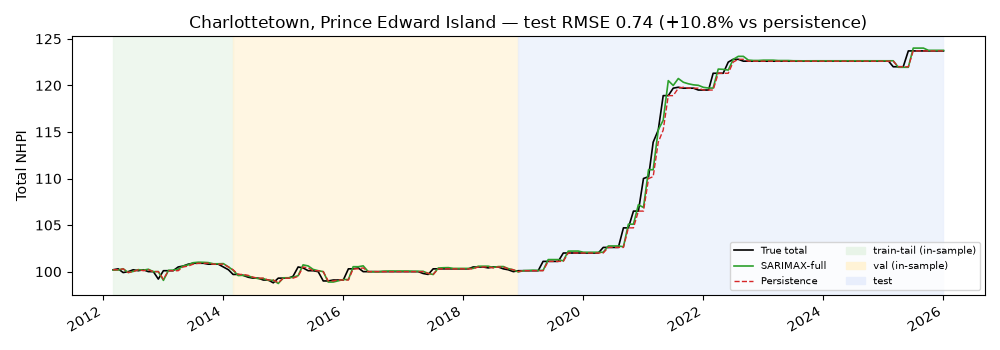

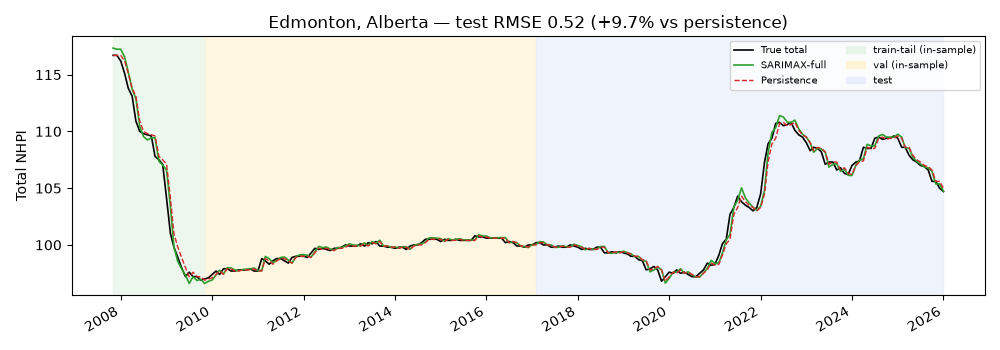

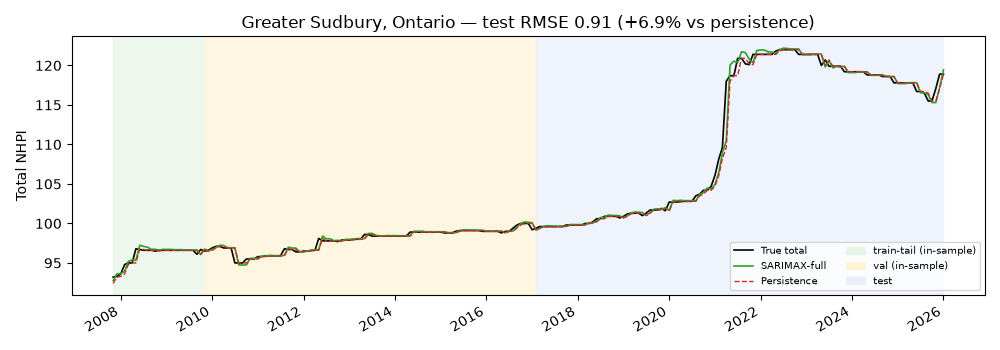

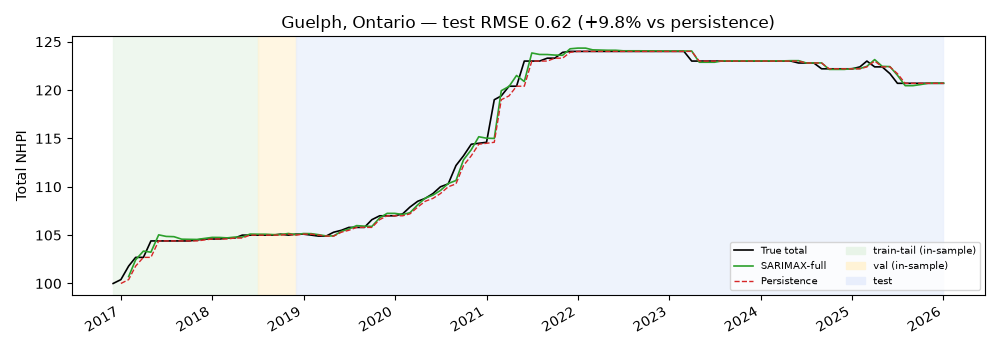

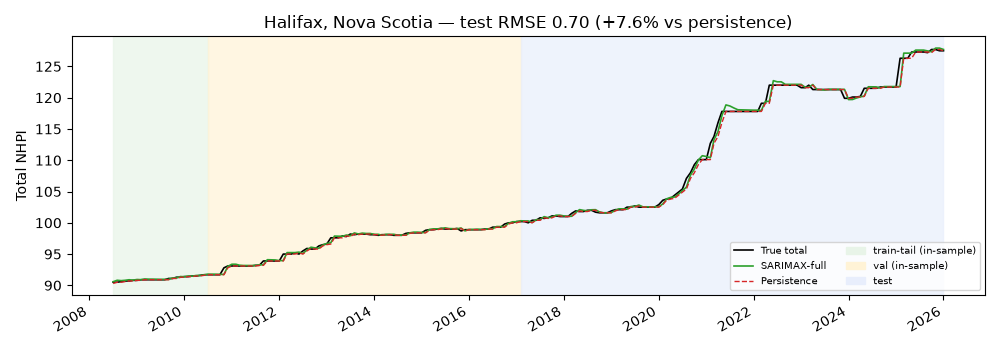

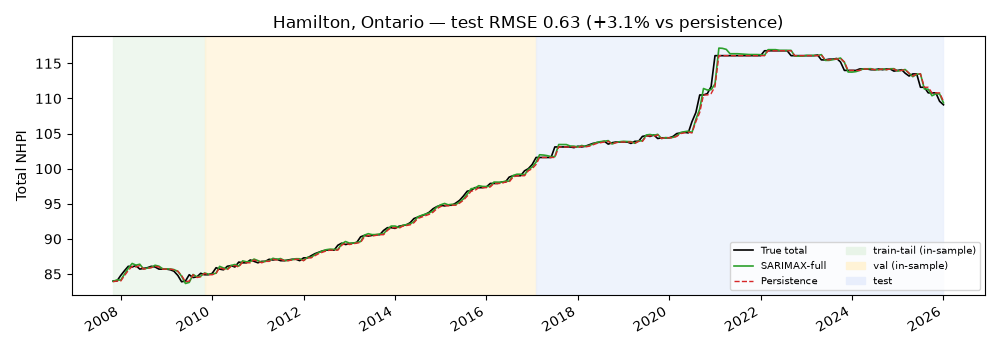

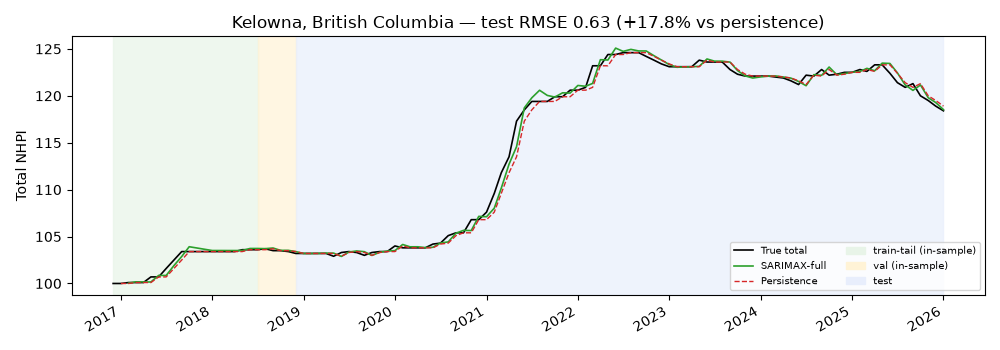

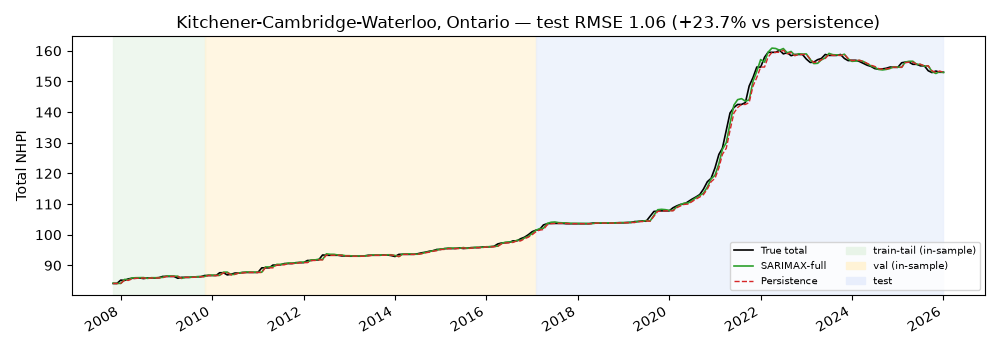

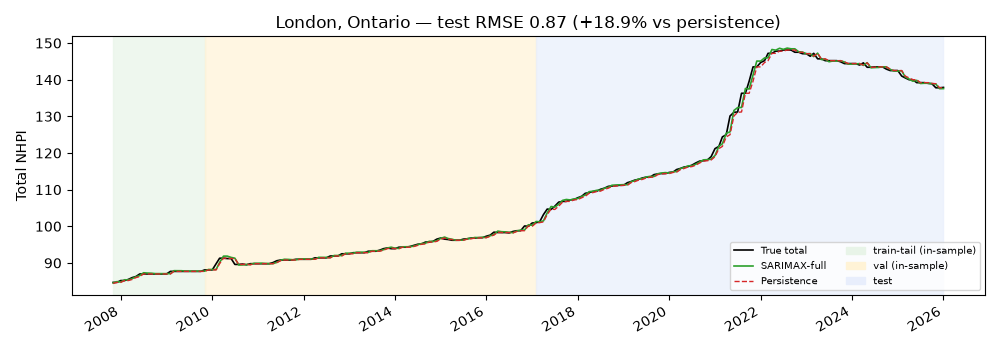

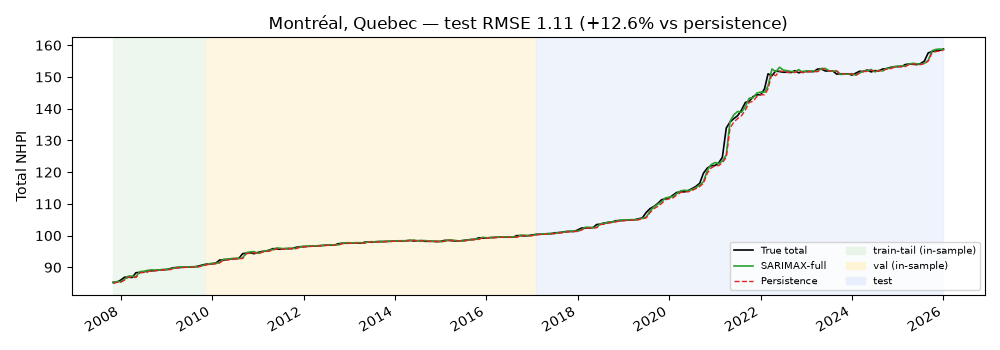

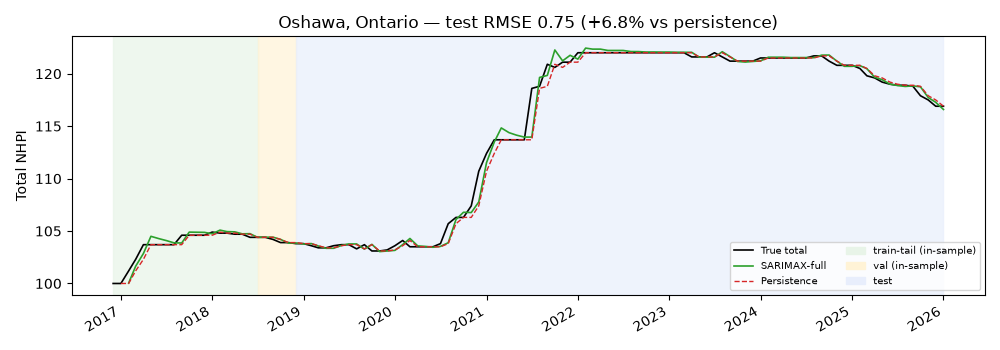

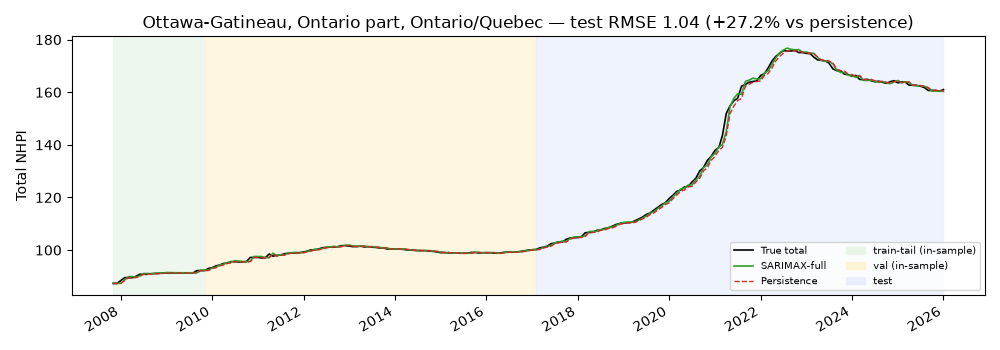

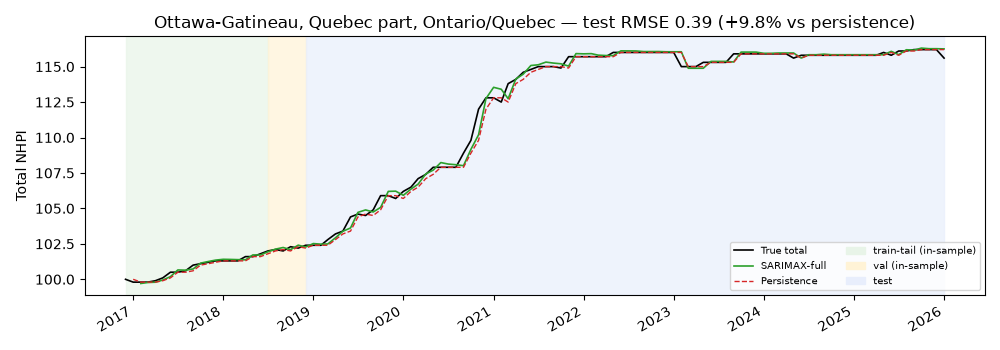

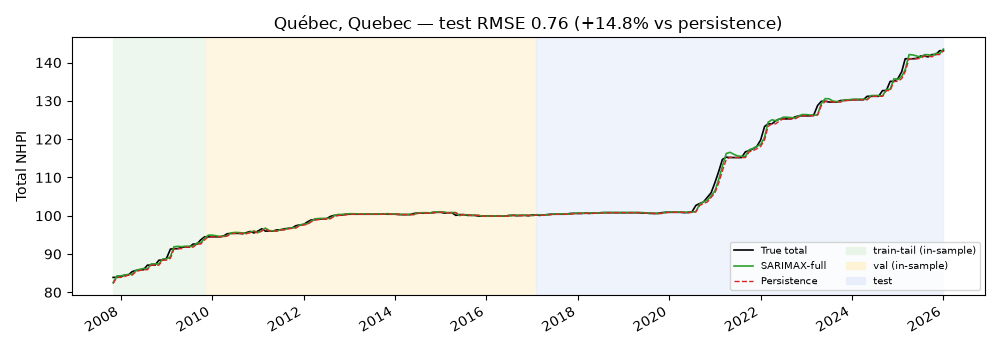

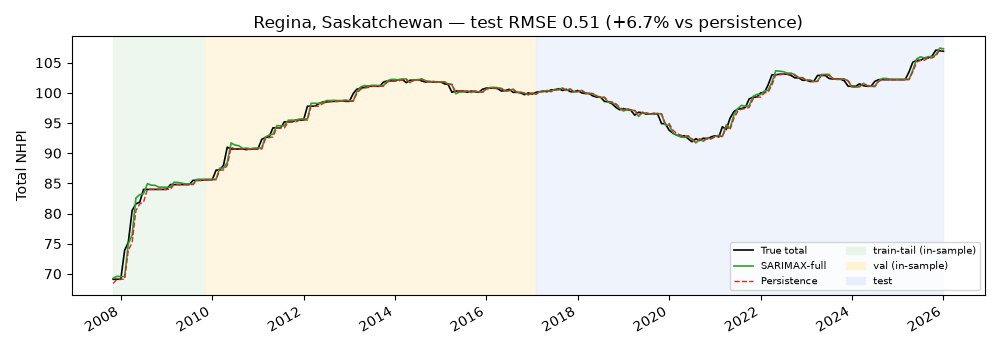

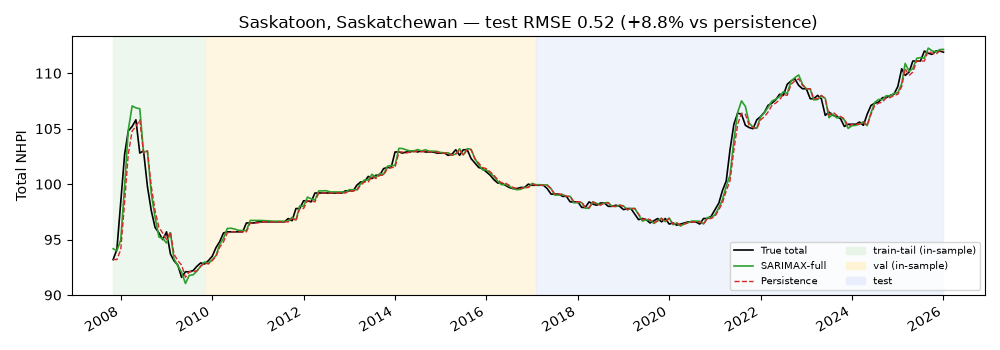

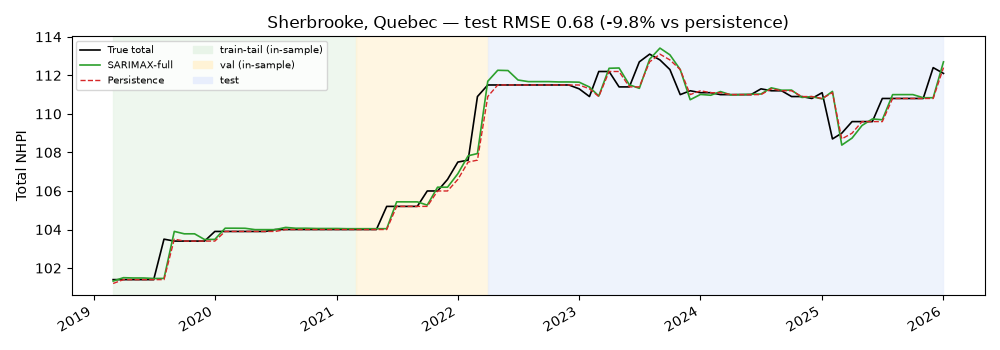

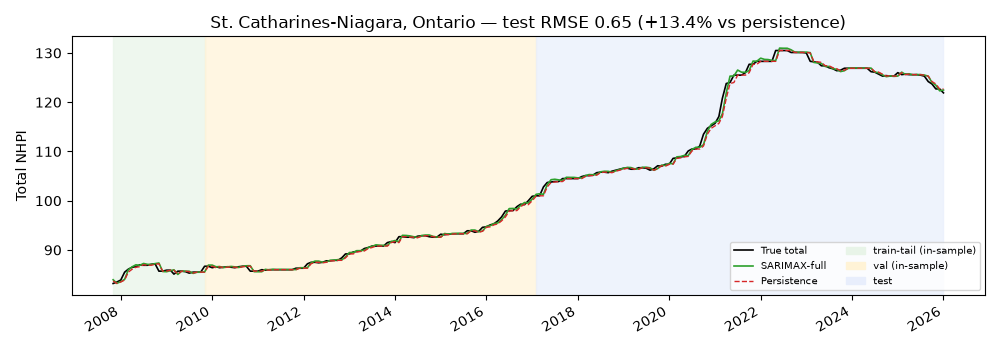

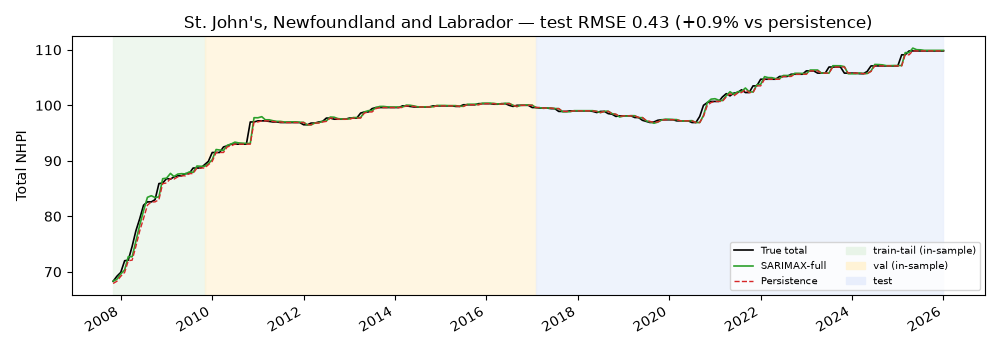

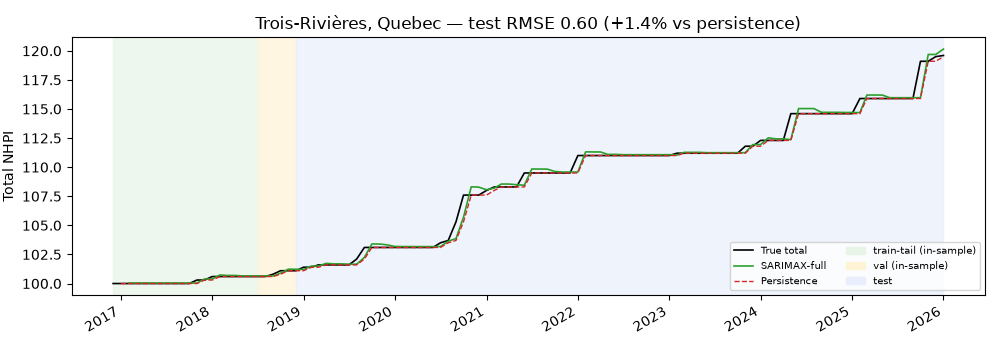

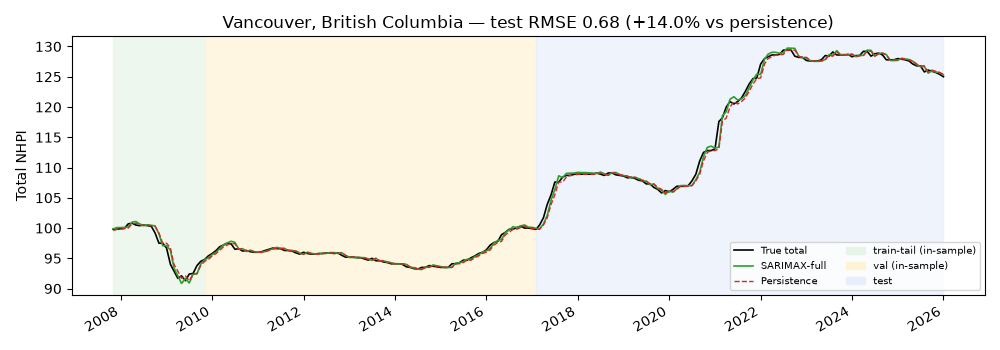

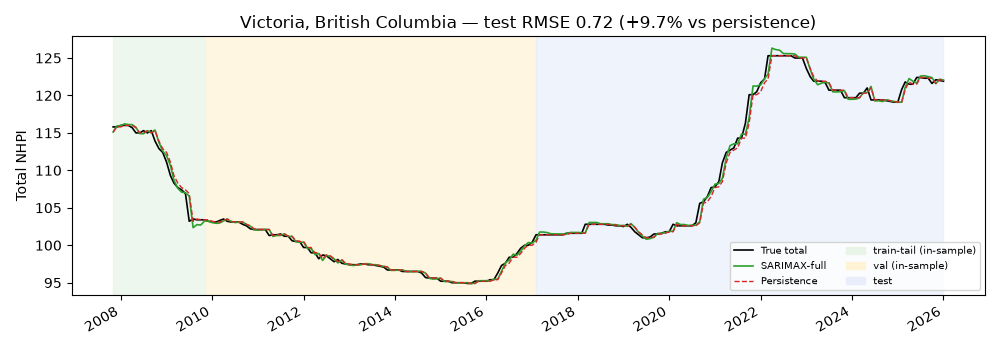

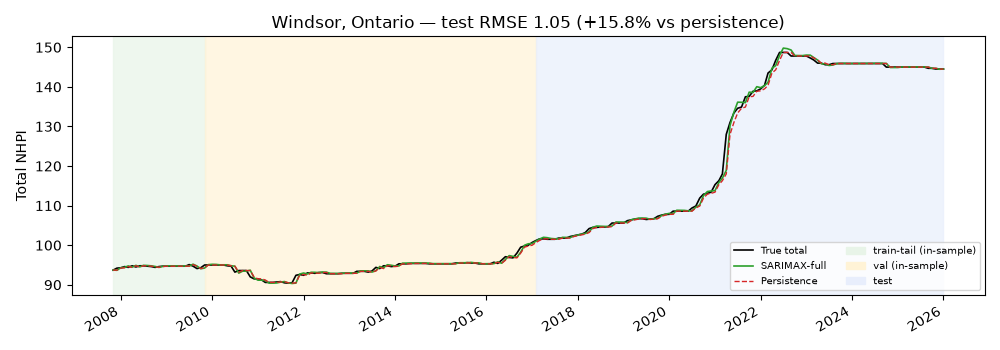

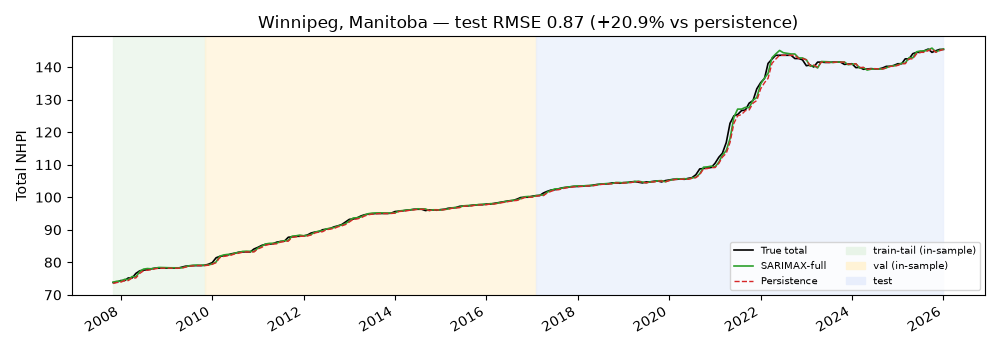

saved 24 plots -> /Users/bigcamel/Oxford/CoCurricular/AGF/ProjectRepositories/canada-housing/notebooks/plots_sarimax_full


In [4]:
import matplotlib

matplotlib.use('Agg')

import matplotlib.pyplot as plt

import matplotlib.patches as mpatches

from IPython.display import Image, display

PLOT_DIR = OUT_DIR / 'plots_sarimax_full'

PLOT_DIR.mkdir(exist_ok=True)

def sanitize(name):

    return ''.join(c if c.isalnum() or c in '-_' else '_' for c in str(name))

saved = []

for cma in sorted(full['cma_canonical'].unique()):

    g = full[full.cma_canonical == cma].sort_values('date')

    tail_start, val_start, test_start = zones[cma]

    g = g[g.date >= tail_start]

    fig, ax = plt.subplots(figsize=(10, 3.5))

    ax.axvspan(tail_start, val_start, color='#e8f4e8', alpha=0.7)

    ax.axvspan(val_start, test_start, color='#fff3d6', alpha=0.7)

    ax.axvspan(test_start, g.date.max(), color='#e8eefc', alpha=0.7)

    p1, = ax.plot(g.date, g.total, label='True total', color='black', lw=1.2)

    p2, = ax.plot(g.date, g.sar_level, label='SARIMAX-full', color='#2ca02c', lw=1.2)

    p3, = ax.plot(g.date, g.y_prev, label='Persistence', color='#d62728', lw=1.0, ls='--')

    zpatches = [mpatches.Patch(color='#e8f4e8', label='train-tail (in-sample)'),

                mpatches.Patch(color='#fff3d6', label='val (in-sample)'),

                mpatches.Patch(color='#e8eefc', label='test')]

    row = met['per_cma'][cma]

    gain = (row['naive'] - row['rmse']) / row['naive'] * 100

    ax.set_title(f"{cma} \u2014 test RMSE {row['rmse']:.2f} ({gain:+.1f}% vs persistence)")

    ax.legend(handles=[p1, p2, p3] + zpatches, fontsize=7, loc='best', ncol=2)

    ax.set_ylabel('Total NHPI')

    fig.autofmt_xdate()

    plt.tight_layout()

    out = PLOT_DIR / f'{sanitize(cma)}.png'

    plt.savefig(out, dpi=100)

    plt.close(fig)

    saved.append(out)

    display(Image(filename=str(out)))

print(f'saved {len(saved)} plots -> {PLOT_DIR}')



In [5]:
per = pd.DataFrame(met['per_cma']).T
per['gain_pct'] = (per['naive'] - per['rmse']) / per['naive'] * 100
per['history'] = np.where(per.index.isin(SUBSET16), 'long-16', 'short-8')
print(per.round(4).sort_values('rmse').to_string())
print()
print('short-history CMAs (8):')
print(per[~per.index.isin(SUBSET16)].round(4).to_string())
beats = int((per['rmse'] < per['naive']).sum())
print(f'\nbeats naive in {beats}/24 CMAs')


                                                 rmse   naive      n  gain_pct  history
Ottawa-Gatineau, Quebec part, Ontario/Quebec   0.3895  0.4319   86.0    9.8164  short-8
St. John's, Newfoundland and Labrador          0.4337  0.4376  108.0    0.8849  long-16
Regina, Saskatchewan                           0.5133  0.5500  108.0    6.6735  long-16
Edmonton, Alberta                              0.5214  0.5771  108.0    9.6617  long-16
Saskatoon, Saskatchewan                        0.5239  0.5741  108.0    8.7529  long-16
Trois-Rivières, Quebec                         0.5961  0.6043   86.0    1.3567  short-8
Guelph, Ontario                                0.6184  0.6853   86.0    9.7636  short-8
Kelowna, British Columbia                      0.6271  0.7626   86.0   17.7723  short-8
Hamilton, Ontario                              0.6293  0.6493  108.0    3.0751  long-16
St. Catharines-Niagara, Ontario                0.6511  0.7517  108.0   13.3798  long-16
Sherbrooke, Quebec              

In [6]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ax = per[['rmse', 'naive']].sort_values('rmse').plot.barh(figsize=(8, 9), color=['#2ca02c', '#d62728'])
ax.set_xlabel('RMSE (index points)')
ax.set_title('sarimax-full vs naive-zero per CMA (test, 24 CMAs)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'sarimax_full_vs_naive.png', dpi=100)
print(f"saved {OUT_DIR / 'sarimax_full_vs_naive.png'}")


saved /Users/bigcamel/Oxford/CoCurricular/AGF/ProjectRepositories/canada-housing/notebooks/sarimax_full_vs_naive.png


In [7]:
import sys
sys.path.insert(0, str(ROOT / 'evaluation'))
from evaluation import calculate_all_metrics

for split, fr in (('test', fr_test), ('train', fr_train)):
    m = calculate_all_metrics(fr.rename(columns={'total_true': 'total_true', 'total_pred': 'total_pred'}), 'total')
    print(f'evaluation.calculate_all_metrics [{split}, total]: ' + ', '.join(f'{k}={v:.4f}' for k, v in m.items()))


evaluation.calculate_all_metrics [test, total]: MDA=0.4419, NMSE=0.0000, NRMSE=0.0003, NMAE=0.0002
evaluation.calculate_all_metrics [train, total]: MDA=0.4142, NMSE=0.0000, NRMSE=0.0001, NMAE=0.0000


/Users/bigcamel/Oxford/CoCurricular/AGF/ProjectRepositories/canada-housing/evaluation/evaluation.py:48: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  directions = df.groupby(group_col, group_keys=False).apply(per_group_directions).dropna()
/Users/bigcamel/Oxford/CoCurricular/AGF/ProjectRepositories/canada-housing/evaluation/evaluation.py:48: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  directions = df.groupby(group_

In [8]:
# Baseline comparison: persistence (delta = 0) vs previous-best mean-3 ensemble vs sarimax-full.
# Mean-3 test16 comes from its committed artifact, cross-checked live against its committed
# eval-schema predictions on the chained mask (no refit). NOTE: the mean-3 test CSV carries
# valid predictions for the 16-subset only (1728/2398) — the old ensemble never scored the 8
# short-history CMAs, which is itself part of the case for the full-panel model below.
mean3 = json.loads((ART_DIR / 'mean3_metrics.json').read_text())
m3 = pd.read_csv(PRED_DIR / 'mean3_predictions_test.csv', parse_dates=['date'])
m3s = m3.sort_values(['cma_canonical', 'date'], kind='mergesort').reset_index(drop=True)
te_sorted = combo[(combo._s == 'test')].sort_values(['cma_canonical', 'date'], kind='mergesort').reset_index(drop=True)
assert (m3s['cma_canonical'].to_numpy() == te_sorted['cma_canonical'].to_numpy()).all()
assert (pd.to_datetime(m3s['date']) == pd.to_datetime(te_sorted['date'])).all()
yprev_te = combo.groupby('cma_canonical')['total'].shift(1)[combo._s == 'test'].to_numpy(float)
# (chained: first test row per CMA uses the last TRAIN value — identical mask convention)
m3_dhat = m3s['total_pred'].to_numpy(float) - yprev_te
m3_dtrue = te_sorted['delta'].to_numpy(float)
ok = np.isfinite(m3_dhat) & np.isfinite(m3_dtrue)
assert int(ok.sum()) == 1728, f'mean3 valid-mask broke: {int(ok.sum())}'
assert set(m3s.loc[ok, 'cma_canonical'].unique()) == set(SUBSET16), 'mean3 covers exactly the 16-subset'
m3_r16 = rmse(m3_dtrue[ok], m3_dhat[ok])
assert abs(m3_r16 - mean3['delta_rmse_16']) < 1e-9, 'mean3 artifact/CSV mismatch'
print(f"{'model':28s} {'test16':>8s} {'test24':>8s} {'gain16':>7s} {'gain24':>7s}")
print(f"{'persistence (delta = 0)':28s} {met['naive_16']:8.4f} {met['naive_24']:8.4f} {'—':>7s} {'—':>7s}")
print(f"{'mean-3 ensemble (prev best)':28s} {m3_r16:8.4f} {'n/a (16-only)':>8s} {(met['naive_16'] - m3_r16) / met['naive_16'] * 100:6.1f}% {'—':>7s}")
print(f"{'sarimax-full (this notebook)':28s} {r16:8.4f} {r24:8.4f} {(met['naive_16'] - r16) / met['naive_16'] * 100:6.1f}% {(met['naive_24'] - r24) / met['naive_24'] * 100:6.1f}%")
print(f'\ncost of dropping the ensemble on test16: {r16 - m3_r16:+.4f} ({(r16 - m3_r16) / m3_r16 * 100:+.1f}%) — ~1.1pp of the 17.2% gain;')
print('mean-3 has no test24 by construction (short-history CMAs never scored) — full coverage is new.')


model                          test16   test24  gain16  gain24
persistence (delta = 0)        0.9564   0.8932       —       —
mean-3 ensemble (prev best)    0.7916 n/a (16-only)   17.2%       —
sarimax-full (this notebook)   0.8003   0.7604   16.3%   14.9%

cost of dropping the ensemble on test16: +0.0087 (+1.1%) — ~1.1pp of the 17.2% gain;
mean-3 has no test24 by construction (short-history CMAs never scored) — full coverage is new.


## Conclusion

One pooled 2-feature Lasso AR (`rollmean_3 + rollmean_12`, $\alpha=0.001$, 7744 full-panel rows) ties the 13-feature R4 head on test
(0.7604 vs 0.7601 on 24; 0.8003 vs 0.8001 on 16 — noise) while covering all 8 short-history CMAs and beating naive by ~15%.
The val-promised −1.8% did not generalize (reported, not hidden); what the search bought is parsimony + full coverage at no accuracy cost.
No ensembles, no foundation models, test scored once.
Against the previous-best mean-3 ensemble (0.7916 on test16, recomputed above on both masks): sarimax-full concedes ~1.1% on test16 — the measured price of dropping TabPFN/GBT — while matching the single-model head, covering all 24 CMAs, and fitting 2 features instead of 3 models.
